In [28]:
from pathlib import Path
from decouple import AutoConfig

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from numpy import dot, array
from numpy.linalg import norm
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [29]:
cwd = Path.cwd()
project_dir = cwd / "langchain" if (cwd / "langchain").is_dir() else cwd
config = AutoConfig(search_path=str(project_dir))
api_key = config("OPENAI_API_KEY")

In [30]:
documents = [
    "Este é o primeiro documento. Ele contém informacoes importantes sobre esse projeto.",
    "Este é o segundo documento. Ele contém informacoes importantes sobre esse projeto.",
    "O terceiro documento oferece uma visao geral dos resultados esperados e métricas de sucesso."
]

In [31]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=50,
    chunk_overlap=10,
    length_function=len
)

chunks = text_splitter.create_documents(documents)

In [32]:
print("\nChunk gerados:")
for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}: {chunk.page_content}")


Chunk gerados:
Chunk 1: Este é o primeiro documento. Ele contém
Chunk 2: contém informacoes importantes sobre esse
Chunk 3: esse projeto.
Chunk 4: Este é o segundo documento. Ele contém informacoes
Chunk 5: importantes sobre esse projeto.
Chunk 6: O terceiro documento oferece uma visao geral dos
Chunk 7: geral dos resultados esperados e métricas de
Chunk 8: de sucesso.


In [33]:
print(f"\nNumero total de chunks: {len(chunks)}")


Numero total de chunks: 8


In [34]:
embeddings = OpenAIEmbeddings(api_key=api_key,model='text-embedding-ada-002')
print(embeddings)

client=<openai.resources.embeddings.Embeddings object at 0x126c63b10> async_client=<openai.resources.embeddings.AsyncEmbeddings object at 0x126c9c410> model='text-embedding-ada-002' dimensions=None deployment='text-embedding-ada-002' openai_api_version=None openai_api_base=None openai_api_type=None openai_proxy=None embedding_ctx_length=8191 openai_api_key=SecretStr('**********') openai_organization=None allowed_special=None disallowed_special=None chunk_size=1000 max_retries=2 request_timeout=None headers=None tiktoken_enabled=True tiktoken_model_name=None show_progress_bar=False model_kwargs={} skip_empty=False default_headers=None default_query=None retry_min_seconds=4 retry_max_seconds=20 http_client=None http_async_client=None check_embedding_ctx_length=True


In [35]:
embedded_chunks = embeddings.embed_documents([chunk.page_content for chunk in chunks])

In [36]:
print(f"\nEmbeddings gerados (mostrando apenas os primeiros 5 elementos de cada):")
for i, embed in enumerate(embedded_chunks):
    print(f"Embedding {i+1}: {embed[:5]}...")


Embeddings gerados (mostrando apenas os primeiros 5 elementos de cada):
Embedding 1: [-0.0018670230638235807, 0.017166996374726295, 0.0011514644138514996, -0.020769629627466202, 0.0009896024130284786]...
Embedding 2: [-0.011761930771172047, 0.023694992065429688, 0.00402485765516758, -0.04278262332081795, -0.004419773817062378]...
Embedding 3: [-0.021568577736616135, -0.006138646509498358, -0.0017646108753979206, -0.02035551145672798, 0.00930461473762989]...
Embedding 4: [-0.002335808938369155, 0.029016893357038498, 0.004630219656974077, -0.035003695636987686, -0.006852980237454176]...
Embedding 5: [-0.006915709003806114, -0.01096267905086279, -0.006355621851980686, -0.02662462554872036, 0.016433773562312126]...
Embedding 6: [-0.016915850341320038, -0.007390168495476246, 0.004423100035637617, -0.019996166229248047, 0.0340905487537384]...
Embedding 7: [-0.024612564593553543, 0.003631029510870576, 0.01579531654715538, -0.025423968210816383, 0.010710523463785648]...
Embedding 8: [-0.03065

In [37]:
print(f"\nNumero de elementos em cada embedding: {len(embedded_chunks[0])}")


Numero de elementos em cada embedding: 1536


In [38]:
def cosine_similarity(vec1, vec2):
    return dot(vec1, vec2)/(norm(vec1) * norm(vec2))

In [39]:
print("\nSimilaridades entre todos os chunks:")
similarities = []

for i in range(len(embedded_chunks)):
    for j in range (i+1, len(embedded_chunks)):
        similarity = cosine_similarity(embedded_chunks[i], embedded_chunks[j])
        similarities.append((i, j, similarity))
        print(f"Similaridade entre o chunk {i+1} e o chunk {j+1}: {similarity:.2f}")


Similaridades entre todos os chunks:
Similaridade entre o chunk 1 e o chunk 2: 0.84
Similaridade entre o chunk 1 e o chunk 3: 0.80
Similaridade entre o chunk 1 e o chunk 4: 0.90
Similaridade entre o chunk 1 e o chunk 5: 0.81
Similaridade entre o chunk 1 e o chunk 6: 0.83
Similaridade entre o chunk 1 e o chunk 7: 0.77
Similaridade entre o chunk 1 e o chunk 8: 0.78
Similaridade entre o chunk 2 e o chunk 3: 0.82
Similaridade entre o chunk 2 e o chunk 4: 0.87
Similaridade entre o chunk 2 e o chunk 5: 0.88
Similaridade entre o chunk 2 e o chunk 6: 0.81
Similaridade entre o chunk 2 e o chunk 7: 0.78
Similaridade entre o chunk 2 e o chunk 8: 0.80
Similaridade entre o chunk 3 e o chunk 4: 0.80
Similaridade entre o chunk 3 e o chunk 5: 0.90
Similaridade entre o chunk 3 e o chunk 6: 0.79
Similaridade entre o chunk 3 e o chunk 7: 0.78
Similaridade entre o chunk 3 e o chunk 8: 0.86
Similaridade entre o chunk 4 e o chunk 5: 0.82
Similaridade entre o chunk 4 e o chunk 6: 0.85
Similaridade entre o c

In [40]:
embedded_chunks_array = array(embedded_chunks)

In [41]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(embedded_chunks_array)

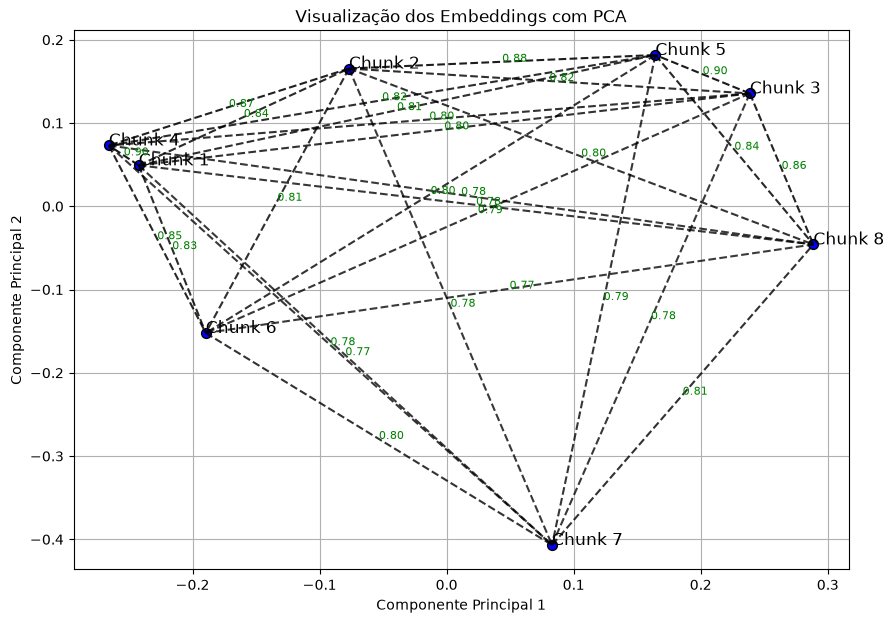

In [42]:
plt.figure(figsize=(10, 7))
plt.scatter(pca_result[:, 0], pca_result[:, 1], c='blue', edgecolor='k', s=50)
for i, chunk in enumerate(chunks):
    plt.text(pca_result[i, 0], pca_result[i, 1], f'Chunk {i+1}', fontsize=12)
for (i, j, similarity) in similarities:
    plt.plot([pca_result[i, 0], pca_result[j, 0]], [pca_result[i, 1], pca_result[j, 1]], 'k--', alpha=similarity)
    mid_x = (pca_result[i, 0] + pca_result[j, 0]) / 2
    mid_y = (pca_result[i, 1] + pca_result[j, 1]) / 2
    plt.text(mid_x, mid_y, f'{similarity:.2f}', fontsize=8, color='green')
plt.title('Visualização dos Embeddings com PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

In [43]:
tsne = TSNE(n_components=2, perplexity=2, max_iter=300)
tsne_result = tsne.fit_transform(embedded_chunks_array)

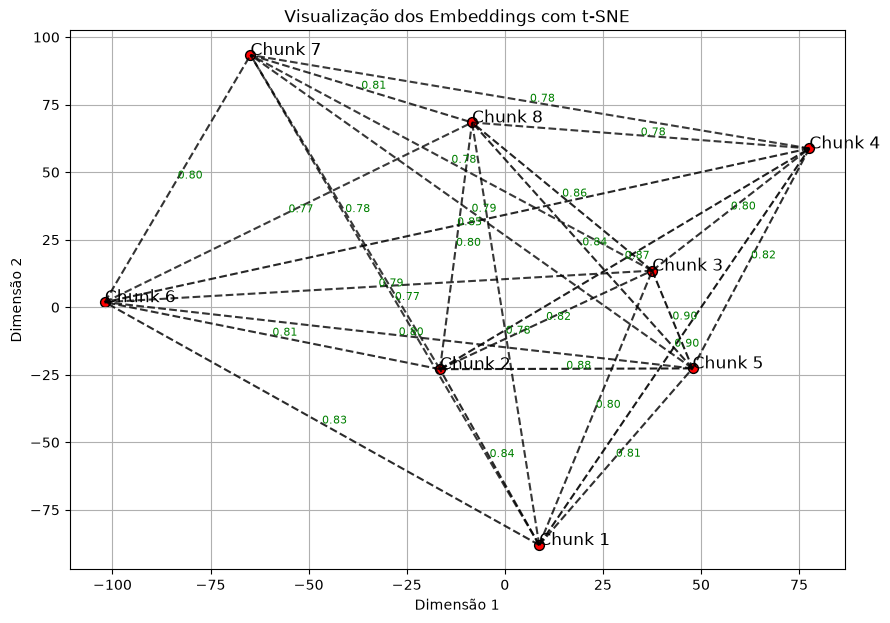

In [44]:
plt.figure(figsize=(10, 7))
plt.scatter(tsne_result[:, 0], tsne_result[:, 1], c='red', edgecolor='k', s=50)
for i, chunk in enumerate(chunks):
    plt.text(tsne_result[i, 0], tsne_result[i, 1], f'Chunk {i+1}', fontsize=12)
for (i, j, similarity) in similarities:
    plt.plot([tsne_result[i, 0], tsne_result[j, 0]], [tsne_result[i, 1], tsne_result[j, 1]], 'k--', alpha=similarity)
    mid_x = (tsne_result[i, 0] + tsne_result[j, 0]) / 2
    mid_y = (tsne_result[i, 1] + tsne_result[j, 1]) / 2
    plt.text(mid_x, mid_y, f'{similarity:.2f}', fontsize=8, color='green')
plt.title('Visualização dos Embeddings com t-SNE')
plt.xlabel('Dimensão 1')
plt.ylabel('Dimensão 2')
plt.grid(True)
plt.show()